# 05. Final forecast

This is the short path from the data to the submission file: Chronos-2 with all weather columns and the raw
interval capped. Run `04_chronos_backtest.ipynb` first if `backtest_30_windows.csv` is missing.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import *

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160, "display.max_columns", 40)
data, weather_fc = load_data()
y = data["y"].to_numpy(float)
FEATURES = [c for c in weather_fc.columns if c != "ds"]
print(len(data), "hours, last one:", data["ds"].iloc[-1])

CAP = 1.0                    # from notebook 04: the lowest Winkler that keeps coverage above 0.95

33480 hours, last one: 2026-10-27 00:00:00


In [2]:
# Pretrained model: no fitting, so the same inputs give the same forecast.
pipe = load_chronos()
out = chronos_predict(pipe, data, weather_fc, FEATURES)
forecast = out["point"]

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading weights:   8%|▊         | 13/170 [00:00<00:01, 126.93it/s]

Loading weights:  15%|█▌        | 26/170 [00:00<00:02, 65.39it/s] 

Loading weights:  21%|██        | 35/170 [00:00<00:01, 72.51it/s]

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 352.97it/s]

In [3]:
# The real interval is much wider than in any backtest window, so its half-width is capped at CAP times
# the median half-width of the same step across the 30 windows. The point forecast does not change.
bt = pd.read_csv("backtest_30_windows.csv")
up = (bt["Chronos+weather hi"] - bt["Chronos+weather"]).groupby(bt["step"]).median().to_numpy() * CAP
dn = (bt["Chronos+weather"] - bt["Chronos+weather lo"]).groupby(bt["step"]).median().to_numpy() * CAP

upper_95 = forecast + np.minimum(out["hi"] - forecast, up)
lower_95 = np.maximum(forecast - np.minimum(forecast - out["lo"], dn), 0)
width = upper_95 - lower_95
print(f"peaks {forecast[:24].max():.0f} / {forecast[24:].max():.0f}, width {width[:24].mean():.0f} / {width[24:].mean():.0f}")

peaks 1080 / 1289, width 659 / 789


format OK
saved AKHLAMOVA_project.csv


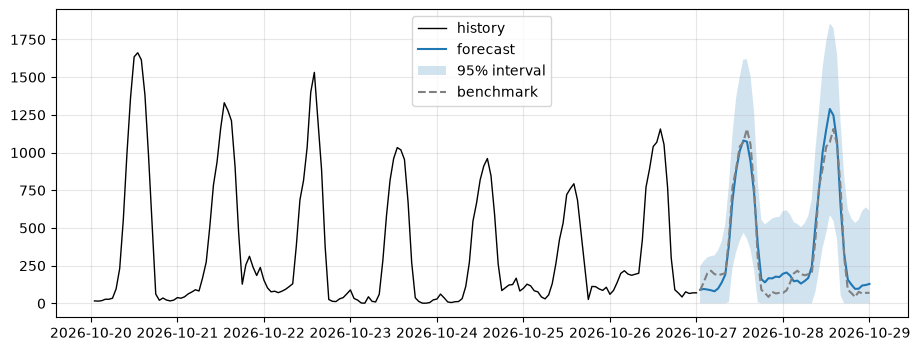

In [4]:
submission = pd.DataFrame({"ds": weather_fc["ds"].dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
                           "lower_95": lower_95, "upper_95": upper_95})
check_submission(submission, weather_fc["ds"])
submission.to_csv(f"{SURNAME}_project.csv", index=False)
print("saved", f"{SURNAME}_project.csv")

plt.plot(data["ds"].iloc[-7 * 24:], y[-7 * 24:], color="black", lw=1, label="history")
plt.plot(weather_fc["ds"], forecast, label="forecast")
plt.fill_between(weather_fc["ds"], lower_95, upper_95, alpha=0.2, label="95% interval")
plt.plot(weather_fc["ds"], snaive(y)[0], color="grey", ls="--", label="benchmark")
plt.legend(); plt.show()